# Seminární práce: Shluková analýza Instagram Reels
**Kurz:** 4IZ210 | Zpracování informací a znalostí  
**Část 2:** Shlukování (K-means, Hierarchické shlukování)  
---

In [1]:
# Import of libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import rand_score


## Identifikace týmu (Team identification)

| Položka | Informace o týmu |
| :--- | :--- |
| **Cvičení (Den a čas):** | Středa 18:00–19:30, učebna SB M15 |
| **Tým a název projektu:** | **Team 6** – *What Makes an Instagram Reel Go Viral?* |
| **Členové týmu:** | Kajetan Franciszek Wielgosz, Tomáš Duchoň, Adam Veselý, Adam Súkala, Natalie Stašková |

# Úvod (Introduction)

### 0. Popis zvoleného datasetu a cíl shlukování (Dataset & Clustering Goals)
Pro zpracování seminární práce jsme zvolili datovou sadu **„What Makes an Instagram Reel Go Viral?“**. Dataset obsahuje celkem **100 000 instancí** reprezentujících výkonnostní a obsahové parametry krátkých videozáznamů (Instagram Reels).  
Cílem této druhé části projektu je pomocí metod shlukování (*unsupervised machine learning*) nalézt přirozené skupiny podobných Instagram Reels. Zaměříme se na příspěvky, které používají trendující audio (`trending_audio = True`), a prozkoumáme, zda se nalezené skupiny liší například vlastnostmi videa, mírou zapojení uživatelů nebo virálností.

### 1. Byznysová hodnota shlukování (Business Value)
* **Segmentace obsahu a archetypy videí:** Výsledky shlukové analýzy mohou tvůrcům obsahu i marketingovým manažerům pomoci lépe porozumět různým typům úspěšných příspěvků a identifikovat charakteristiky jednotlivých skupin.
* **Ověření geometrické separace virality:** Shlukování ukazuje přirozené podobnosti a souvislosti v datech bez vlivu učitele; samo o sobě sice neprokazuje, že určitá vlastnost virálnost přímo způsobuje (kauzalita), ale umožňuje posoudit, zda virální obsah tvoří samostatný kompaktní shluk.

### 2. Zdroj dat (Data Source)
* **Veřejný zdroj:** Dataset je veřejně dostupný na platformě Kaggle:  
  [https://www.kaggle.com/datasets/deepeshkansotia/what-makes-an-instagram-reel-go-viral](https://www.kaggle.com/datasets/deepeshkansotia/what-makes-an-instagram-reel-go-viral)
* **Lokální soubor:** `instagram data.csv`

## Přizpůsobení úlohy (Customization)

### 1. Zvolená podmnožina dat (*Chosen subset of data*)
* **Definice podmnožiny:** Instagram Reels s trendujícím audiem (`trending_audio = True`).
* **Velikost podmnožiny:** Tato podmnožina obsahuje celkem **49 917 záznamů** (téměř polovina celého datasetu).
* **Reprezentativní vzorek pro modelování:** Kvůli vysoké výpočetní a paměťové náročnosti hierarchického shlukování jsme z ní náhodně vybrali vzorek **2 000 záznamů** pomocí parametru `random_state = 42`.

### 2. Instance zájmu (*Instance of interest*)
* **Původní index v datech:** `87912` (první záznam ve vytvořeném vzorku `X_cluster_scaled`).
* **Identifikátor příspěvku (`reel_id`):** `76a9ff66-9546-4836-ae2a-36ca7115a6f1`
* **Cílová třída:** Nevirální příspěvek (`is_viral = 0`).

### 3. Atribut zájmu (*Attribute of interest*)
* **Zvolený atribut:** Cílový atribut virality **`is_viral`**.
* **Definice:** Hodnota $1$ označuje virální Reel s `virality_score` $\ge 75$, hodnota $0$ nevirální Reel.
* **Využití:** Tento atribut **nebyl použit při tvorbě shluků** (učení bez učitele); využili jsme ho výhradně k jejich následnému porovnání a vyhodnocení.

### 4. Matice nákladů (*Cost matrix*)
Shlukování nepředpovídá přímo třídu virální/nevirální, proto nákladová matice neovlivňuje tvorbu shluků. Protože ji šablona požaduje, uvádíme stejnou referenční nákladovou matici jako v klasifikační části (zde slouží pouze jako doplňující kontext a nepoužívá se při optimalizaci shlukování):

| | Skutečnost: Pozitivní ($y=1$, Virální) | Skutečnost: Negativní ($y=0$, Nevirální) |
| :--- | :--- | :--- |
| **Predikce: Pozitivní ($\hat{y}=1$)** | $TP = 0\text{ Kč}$ (Správný zásah) | $FP = 100\text{ Kč}$ (Zbytečná investice do boostu) |
| **Predikce: Negativní ($\hat{y}=0$)** | $FN = 300\text{ Kč}$ (Ušlý zisk z virálního potenciálu) | $TN = 0\text{ Kč}$ (Správné nezainvestování) |

> **Poznámka k nákladové matici:** V úloze shlukování matice nákladů nevstupuje do optimalizačního kritéria a slouží pouze pro návaznost na klasifikaci.

# Předzpracování dat (Data preprocessing)

## Příprava dat pro shlukování (Preprocessing for Unsupervised ML)
V rámci přípravy dat pro nepodmíněné učení (shlukování) provádíme následující kroky:
1. **Filtrování podmnožiny:** Výběr záznamů s `trending_audio == True` (49 917 řádků).
2. **Výběr vzorku (Sampling):** Náhodný výběr reprezentativního vzorku 2 000 záznamů (`random_state = 42`) pro eliminaci extrémní paměťové náročnosti hierarchického shlukování.
3. **Odstranění neprediktivních a cílových atributů:** Odstranění cílových sloupců (`virality_score`, `is_viral`), konstantního sloupce `trending_audio` a textových identifikátorů (`reel_id`, `creator_id`), aby nedocházelo k ovlivnění modelů.
4. **Min-Max škálování:** Normalizace všech numerických příznaků do intervalu $\langle 0; 1 \rangle$ pomocí `MinMaxScaler`.
5. **Export předzpracovaných dat:** Uložení do souboru `data_clustering_processed.csv`.

In [3]:
# 1. Načtení dat a výběr zvolené podmnožiny dat
df = pd.read_csv('instagram data.csv')

# Uložení identifikátorů pro dohledání instance zájmu
ids = df[['reel_id', 'creator_id']].copy()

# Binarizace cílového atributu (bude se hodit pro evaluaci Rand Indexem)
df['is_viral'] = (df['virality_score'] >= 75.0).astype(int)

# Výběr zvolené podmnožiny: příspěvky s trendujícím audiem (trending_audio == 1)
df_cluster_raw = df[df['trending_audio'] == 1].copy()

# Pro shlukování odstraníme cílové atributy, konstantní sloupec trending_audio a ID
X_cluster = df_cluster_raw.drop(columns=['virality_score', 'is_viral', 'trending_audio', 'reel_id', 'creator_id'])

# Převod booleovských sloupců (True/False) na 1/0
bool_cols = X_cluster.select_dtypes(include=['bool']).columns
X_cluster[bool_cols] = X_cluster[bool_cols].astype(int)

print(f"Původní počet řádků: {df.shape[0]}")
print(f"Počet řádků ve vybrané podmnožině (trending_audio == 1): {X_cluster.shape[0]}")
display(X_cluster.head(3))


Původní počet řádků: 100000
Počet řádků ve vybrané podmnožině (trending_audio == 1): 49917


,creator_followers,posting_time,reel_length_sec,hook_strength_score,caption_length,hashtags_count,audio_popularity_score,video_quality_score,editing_quality_score,avg_watch_time_sec,...,rewatch_rate,likes,comments,shares,saves,engagement_rate,impressions,reach,non_follower_reach_ratio,explore_page_boost
0,4208388,3,31,0.451657,0,20,0.399659,0.726317,0.765592,54.586401,...,0.855201,779301,30002,16741,21305,0.884296,75968410,39007279,0.960121,0
2,2624351,0,13,0.019949,205,6,0.697575,0.818374,0.974982,9.967664,...,0.432886,925249,12046,13883,13444,0.057583,75215994,82019789,0.101694,1
5,4996414,19,35,0.617921,11,4,0.268955,0.414631,0.954329,39.977965,...,0.534595,687069,33137,2724,18874,0.940290,52085431,52774412,0.556180,0


In [26]:
# Vybereme 2 000 řádků, aby hierarchické shlukování nebylo příliš náročné
sample_index = X_cluster.sample(n=2000, random_state=42).index

# Příznaky, virálnost a ID vzorku držíme odděleně, ale se stejnými indexy
X_cluster_sample = X_cluster.loc[sample_index].copy()
y_cluster_sample = df_cluster_raw.loc[sample_index, "is_viral"]
ids_cluster_sample = ids.loc[sample_index]

# Převedeme hodnoty příznaků do rozsahu 0 až 1
cluster_scaler = MinMaxScaler()

X_cluster_scaled = pd.DataFrame(
    cluster_scaler.fit_transform(X_cluster_sample),
    columns=X_cluster_sample.columns,
    index=X_cluster_sample.index
)

print("Počet řádků ve vzorku:", X_cluster_scaled.shape[0])
print("Počet příznaků:", X_cluster_scaled.shape[1])
print("Rozsah hodnot:", X_cluster_scaled.min().min(), "až", X_cluster_scaled.max().max())

display(X_cluster_scaled.head())

# Uložíme aktuální vzorek po Min-Max škálování
X_cluster_scaled.to_csv("data_clustering_processed.csv", index=True)

print("Aktuální předzpracovaná data byla uložena.")

Počet řádků ve vzorku: 2000
Počet příznaků: 22
Rozsah hodnot: 0.0 až 1.0000000000000002


,creator_followers,posting_time,reel_length_sec,hook_strength_score,caption_length,hashtags_count,audio_popularity_score,video_quality_score,editing_quality_score,avg_watch_time_sec,...,rewatch_rate,likes,comments,shares,saves,engagement_rate,impressions,reach,non_follower_reach_ratio,explore_page_boost
87912,0.994475,0.478261,0.181818,0.872425,0.816667,0.200000,0.373917,0.551053,0.822107,0.706921,...,0.445833,0.642028,0.780204,0.408638,0.670746,0.410104,0.198862,0.563655,0.093381,0.0
58026,0.742430,0.173913,0.763636,0.966167,0.143333,0.133333,0.554531,0.713279,0.437557,0.377767,...,0.878585,0.836030,0.577642,0.366482,0.536497,0.999649,0.389617,0.650089,0.936945,0.0
9206,0.513893,0.173913,0.563636,0.911348,0.673333,0.033333,0.655807,0.392326,0.110421,0.500070,...,0.218210,0.895443,0.517094,0.126403,0.495815,0.365626,0.801158,0.527263,0.770086,0.0
23201,0.893927,0.260870,0.072727,0.669944,0.610000,0.266667,0.658179,0.358060,0.646466,0.920481,...,0.883193,0.036447,0.225080,0.066342,0.238021,0.660710,0.681773,0.955889,0.147805,1.0
92655,0.706363,0.043478,0.709091,0.093953,0.520000,0.233333,0.065594,0.442483,0.292679,0.578791,...,0.500796,0.294439,0.614051,0.330305,0.850612,0.264104,0.618274,0.192144,0.457452,0.0


Aktuální předzpracovaná data byla uložena.


# Modelování (Modeling)

V této části aplikujeme dva rozdílné shlukovací algoritmy:
1. **K-means** (centroidový algoritmus optimalizující vnitřní rozptyl WCSS),
2. **Hierarchické aglomerativní shlukování** (hierarchický přístup s Wardovou metodou).

Cílový atribut virality `is_viral` ani skóre virality nejsou v souladu se zásadami učení bez učitele zahrnuty do shlukování.

### Model 1: K-means shlukování (K-means clustering)
Pro nalezení optimálního počtu shluků $k$ testujeme rozmezí $k \in \langle 2; 10 \rangle$:
* **Elbow metoda** (křivka setrvačnosti / WCSS – *Within-Cluster Sum of Squares*),
* **Silhouette score** (analýza separace a vnitřní kompaktnosti shluků).

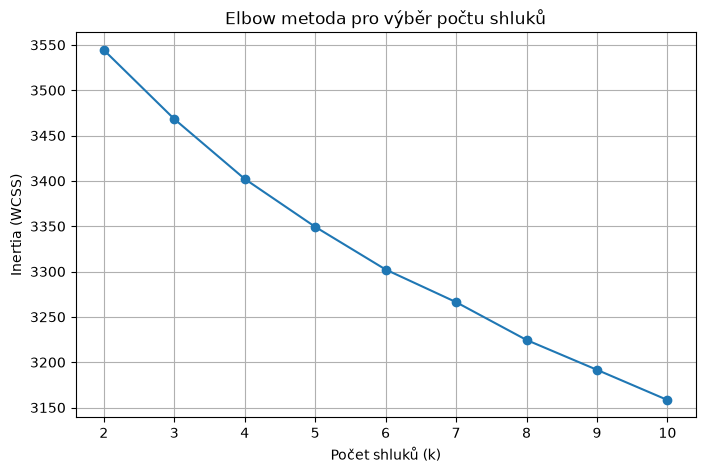

In [13]:
# Otestujeme počet shluků od 2 do 10
k_values = range(2, 11)
inertias = []

for k in k_values:
    kmeans_model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans_model.fit(X_cluster_scaled)
    inertias.append(kmeans_model.inertia_)

# Elbow graf
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Počet shluků (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow metoda pro výběr počtu shluků")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

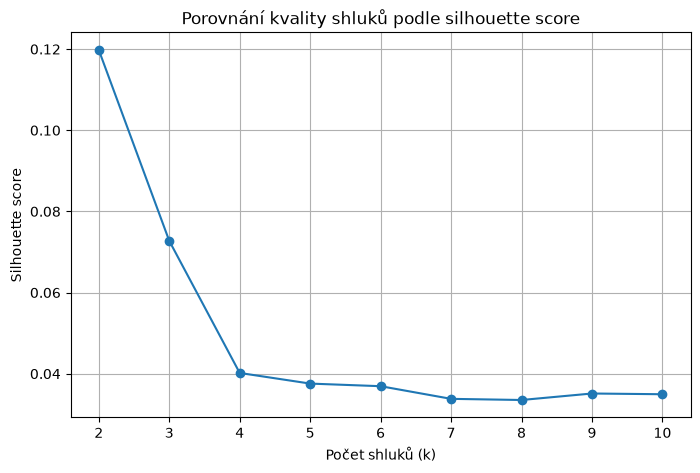

k = 2: silhouette score = 0.120
k = 3: silhouette score = 0.073
k = 4: silhouette score = 0.040
k = 5: silhouette score = 0.038
k = 6: silhouette score = 0.037
k = 7: silhouette score = 0.034
k = 8: silhouette score = 0.034
k = 9: silhouette score = 0.035
k = 10: silhouette score = 0.035


In [15]:
from sklearn.metrics import silhouette_score

silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_cluster_scaled)

    score = silhouette_score(
        X_cluster_scaled,
        labels,
        sample_size=1000,
        random_state=42
    )
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Počet shluků (k)")
plt.ylabel("Silhouette score")
plt.title("Porovnání kvality shluků podle silhouette score")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

for k, score in zip(k_values, silhouette_scores):
    print(f"k = {k}: silhouette score = {score:.3f}")

In [16]:
# Finální model K-means se dvěma shluky
best_k = 2

kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_labels = pd.Series(
    kmeans_final.fit_predict(X_cluster_scaled),
    index=X_cluster_scaled.index,
    name="cluster"
)

print("Počet Reelů v jednotlivých shlucích:")
display(kmeans_labels.value_counts().sort_index())

Počet Reelů v jednotlivých shlucích:


cluster
0    1039
1     961
Name: count, dtype: int64

### Model 2: Hierarchické shlukování (Hierarchical clustering – Ward)
Druhým přístupem je aglomerativní hierarchické shlukování s **Wardovou metodou**, která v každém kroku spojuje dvojici shluků vedoucí k minimálnímu nárůstu celkového rozptylu.  
Níže rovněž sledujeme průběh WCSS při různém počtu shluků.

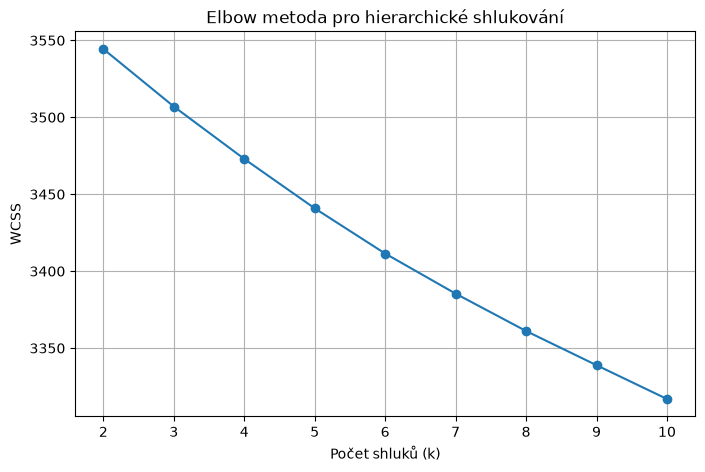

In [25]:
# WCSS pro hierarchické shlukování při různém počtu shluků
hierarchical_k_values = range(2, 11)
hierarchical_wcss = []

for k in hierarchical_k_values:
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    labels = model.fit_predict(X_cluster_scaled)

    wcss = 0
    for cluster_id in np.unique(labels):
        cluster_data = X_cluster_scaled.iloc[labels == cluster_id]
        centroid = cluster_data.mean(axis=0)
        wcss += ((cluster_data - centroid) ** 2).to_numpy().sum()

    hierarchical_wcss.append(wcss)

# Elbow graf pro hierarchické shlukování
plt.figure(figsize=(8, 5))
plt.plot(
    hierarchical_k_values,
    hierarchical_wcss,
    marker="o"
)
plt.xlabel("Počet shluků (k)")
plt.ylabel("WCSS")
plt.title("Elbow metoda pro hierarchické shlukování")
plt.xticks(list(hierarchical_k_values))
plt.grid(True)
plt.show()

> **Interpretace volby počtu shluků pro hierarchické shlukování:**  
> Elbow graf hierarchického shlukování nevykazuje výrazný zlom; WCSS klesá postupně se zvyšujícím se počtem shluků. Počet shluků jsme proto zvolili podle dendrogramu, který ukazuje dvě hlavní větve, a také proto, abychom mohli výsledek porovnat s K-means ($k = 2$).  
> *Silhouette score* $0{,}120$ vyšlo nejlépe pro K-means při $k = 2$; tento výsledek proto bereme jako doplňující vodítko, nikoli jako přímé hodnocení hierarchického modelu.

In [18]:
# Hierarchické shlukování se dvěma shluky
hierarchical_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

hierarchical_labels = pd.Series(
    hierarchical_model.fit_predict(X_cluster_scaled),
    index=X_cluster_scaled.index,
    name="cluster"
)

print("Počet Reelů v jednotlivých hierarchických shlucích:")
display(hierarchical_labels.value_counts().sort_index())

Počet Reelů v jednotlivých hierarchických shlucích:


cluster
0    1039
1     961
Name: count, dtype: int64

# Vyhodnocení modelů (Evaluation)

## Globální vyhodnocení (Global evaluation)
V rámci globálního vyhodnocení posuzujeme shodu vytvořených shluků s externím cílovým atributem virality (`is_viral`) pomocí metriky **Rand index** a porovnáním relativního zastoupení virálních videí v jednotlivých shlucích.

### Evaluace modelu 1: K-means shlukování
*Výpočet Rand indexu a kontingenční tabulky vůči atributu virality `is_viral`:*

In [17]:
# Porovnáme shluky s cílovou proměnnou is_viral,
# která nebyla použita při tvorbě shluků
y_aligned = y_cluster_sample.loc[kmeans_labels.index]

rand = rand_score(y_aligned, kmeans_labels)
print(f"Rand index: {rand:.3f}")

# Počet virálních a nevirálních Reelů v každém shluku
pocty = pd.crosstab(
    kmeans_labels,
    y_aligned,
    rownames=["Shluk"],
    colnames=["Virálnost"]
).rename(columns={0: "Nevirální", 1: "Virální"})

print("Počty v jednotlivých shlucích:")
display(pocty)

# Podíl kategorií uvnitř každého shluku v procentech
podily = (
    pd.crosstab(kmeans_labels, y_aligned, normalize="index")
    .rename(columns={0: "Nevirální (%)", 1: "Virální (%)"})
    * 100
).round(1)

print("Podíly uvnitř jednotlivých shluků:")
display(podily)

Rand index: 0.500
Počty v jednotlivých shlucích:


Virálnost,Nevirální,Virální
Shluk,,
0,772,267
1,706,255


Podíly uvnitř jednotlivých shluků:


is_viral,Nevirální (%),Virální (%)
cluster,,
0,74.3,25.7
1,73.5,26.5


> **Zhodnocení výsledků K-means:**  
> K-means rozdělil vzorek do dvou podobně velkých shluků. Podíl virálních Reelů byl v prvním shluku **25,7 %** a ve druhém **26,5 %**, takže se mezi shluky téměř nelišil.  
> **Rand index dosáhl hodnoty 0,500**, což ukazuje na slabou shodu mezi shluky a rozdělením na virální a nevirální Reels.

### Evaluace modelu 2: Hierarchické shlukování
*Výpočet Rand indexu a kontingenční tabulky vůči atributu virality `is_viral`:*

In [19]:
# Srovnáme hierarchické shluky s virálností
y_hier_aligned = y_cluster_sample.loc[hierarchical_labels.index]

rand_hierarchical = rand_score(y_hier_aligned, hierarchical_labels)
print(f"Rand index: {rand_hierarchical:.3f}")

# Počty virálních a nevirálních Reelů v jednotlivých shlucích
pocty_hierarchical = pd.crosstab(
    hierarchical_labels,
    y_hier_aligned,
    rownames=["Shluk"],
    colnames=["Virálnost"]
).rename(columns={0: "Nevirální", 1: "Virální"})

print("Počty v jednotlivých hierarchických shlucích:")
display(pocty_hierarchical)

# Procentuální zastoupení virálních a nevirálních Reelů
podily_hierarchical = (
    pd.crosstab(
        hierarchical_labels,
        y_hier_aligned,
        normalize="index"
    ).rename(columns={0: "Nevirální (%)", 1: "Virální (%)"}) * 100
).round(1)

print("Podíly uvnitř hierarchických shluků:")
display(podily_hierarchical)

Rand index: 0.500
Počty v jednotlivých hierarchických shlucích:


Virálnost,Nevirální,Virální
Shluk,,
0,772,267
1,706,255


Podíly uvnitř hierarchických shluků:


is_viral,Nevirální (%),Virální (%)
cluster,,
0,74.3,25.7
1,73.5,26.5


> **Zhodnocení výsledků hierarchického shlukování:**  
> Hierarchické shlukování dosáhlo **Rand indexu 0,500**. Podíl virálních Reelů byl v jeho shlucích **25,7 %** a **26,5 %**, stejně jako u K-means.  
> Ani tato metoda tedy v našem vzorku nevytvořila shluky, které by se výrazně lišily podle virálnosti.

## Lokální vyhodnocení (Local evaluation)
Klasifikace vybrané instance zájmu do shluků pomocí obou vytrénovaných modelů:

In [21]:
# Vybereme první Reel z použitého vzorku
instance_index = X_cluster_scaled.index[0]

print("Index Reelů:", instance_index)
print("Reel ID:", ids_cluster_sample.loc[instance_index, "reel_id"])
print("Virální podle cílové proměnné:", y_cluster_sample.loc[instance_index])
print("Shluk podle K-means:", kmeans_labels.loc[instance_index])
print("Shluk podle hierarchického modelu:", hierarchical_labels.loc[instance_index])

Index Reelů: 87912
Reel ID: 76a9ff66-9546-4836-ae2a-36ca7115a6f1
Virální podle cílové proměnné: 0
Shluk podle K-means: 1
Shluk podle hierarchického modelu: 1


# Vysvětlitelnost modelů (Explanation)

## Globální vysvětlení (Global explanation)

### Globální vysvětlení: K-means (Centroidy a profily shluků)
*Interpretace finálních shluků na základě jejich těžišť (průměrných hodnot vlastností) a velikostí shluků:*

In [22]:
# Porovnáme průměrné hodnoty vybraných vlastností v obou shlucích
profile_features = [
    "creator_followers",
    "reel_length_sec",
    "hook_strength_score",
    "caption_length",
    "hashtags_count",
    "audio_popularity_score",
    "avg_watch_time_sec",
    "retention_rate",
    "completion_rate",
    "rewatch_rate",
    "likes",
    "comments",
    "shares",
    "saves",
    "engagement_rate",
    "reach"
]

kmeans_profile = (
    X_cluster_sample
    .groupby(kmeans_labels)[profile_features]
    .mean()
    .T
)

kmeans_profile.columns = [
    f"Shluk {cluster}" for cluster in kmeans_profile.columns
]

display(kmeans_profile.round(2))

,Shluk 0,Shluk 1
creator_followers,2500758.96,2494093.32
reel_length_sec,32.15,33.18
hook_strength_score,0.50,0.49
caption_length,149.48,149.35
hashtags_count,15.23,14.50
audio_popularity_score,0.50,0.49
avg_watch_time_sec,30.29,30.23
retention_rate,0.49,0.50
completion_rate,0.51,0.51
rewatch_rate,0.49,0.48


> **Interpretace profilů shluků (K-means):**  
> Průměrné hodnoty vybraných vlastností jsou v obou shlucích velmi podobné. Menší rozdíly jsou například v délce Reelů, počtu sdílení a dosahu, ale celkově shluky nevytvářejí jasně odlišné profily. To odpovídá i podobnému podílu virálních Reelů v obou skupinách.

### Globální vysvětlení: Hierarchické shlukování (Dendrogram a shoda modelů)
*Vykreslení dendrogramu hierarchického shlukování a posouzení shody rozdělení mezi oběma algoritmy:*

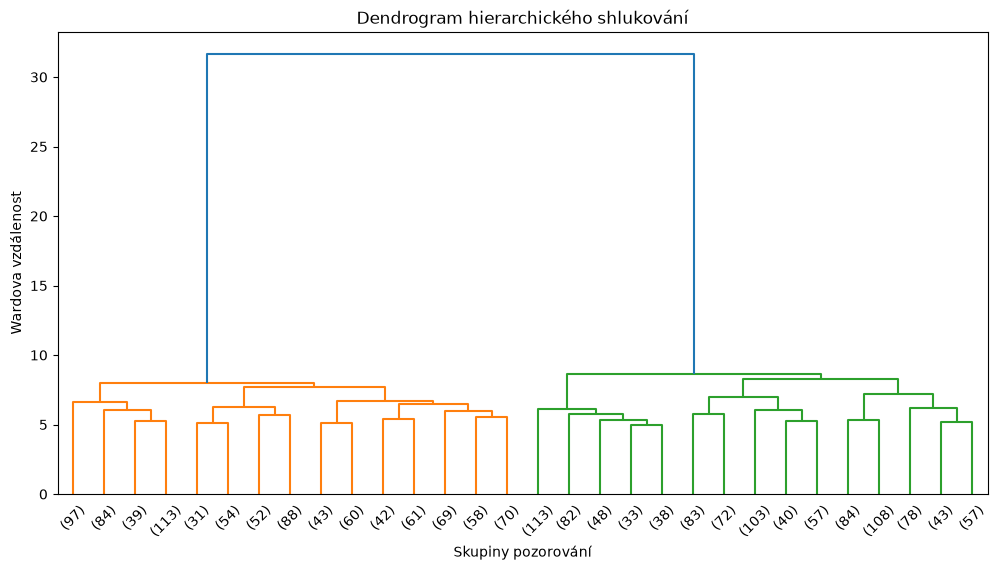

In [23]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Vytvoříme hierarchii shluků metodou Ward
linkage_matrix = linkage(X_cluster_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Dendrogram hierarchického shlukování")
plt.xlabel("Skupiny pozorování")
plt.ylabel("Wardova vzdálenost")
plt.show()

> **Interpretace dendrogramu:**  
> Dendrogram ukazuje dvě hlavní větve, které se spojí až při výrazně větší Wardově vzdálenosti než menší skupiny uvnitř větví. To podporuje volbu dvou shluků.  
> Vzhledem k nízkému *silhouette score* a *Rand indexu* $0{,}500$ však toto rozdělení dobře neodpovídá virálnosti Reelů.

In [24]:
from sklearn.metrics import adjusted_rand_score

shoda_algoritmu = adjusted_rand_score(
    kmeans_labels,
    hierarchical_labels
)

print(f"Shoda rozdělení K-means a hierarchického shlukování: {shoda_algoritmu:.3f}")

Shoda rozdělení K-means a hierarchického shlukování: 1.000


## Lokální vysvětlení (Local explanation)
*Využití obou modelů pro zařazení instance zájmu do shluku a detailní komentář:*

> **Interpretace přiřazení instance zájmu:**  
> Vybraný Reel s ID `76a9ff66-9546-4836-ae2a-36ca7115a6f1` je nevirální (`is_viral = 0`).  
> * Oba algoritmy jej shodně zařadily do **shluku 1**.  
> * Algoritmy se shodly také na celkovém rozdělení vzorku (**Adjusted Rand index = 1,000**).  
> * Shluk 1 obsahuje **26,5 %** virálních Reelů, což je prakticky totožné s celkovým podílem virálních videí v celém vzorku (26,1 %). Toto zařazení proto neznamená, že shluk spolehlivě rozlišuje virální a nevirální příspěvky.

# Závěr (Conclusion)

### Shrnutí výsledků a zodpovězení klíčových otázek

#### 1. Které shlukování poskytlo nejužitečnější výsledek? (*Which clustering provided the most useful result?*)
**K-means i hierarchické shlukování** rozdělily Reels do stejného počtu shluků a vytvořily naprosto totožné rozdělení instancí (**Adjusted Rand Index = 1,000**).  
* **Rozlišení virality:** Žádná z metod jasně neoddělila virální Reels od nevirálních – podíl virálních příspěvků byl v obou shlucích téměř identický (**25,7 % vs. 26,5 %**). Obě metody proto vyšly z hlediska rozpoznání virálnosti rovnocenně a jejich přínos pro separaci virálního obsahu je omezený.  
* **Přidaná hodnota vizualizace:** Hierarchické shlukování navíc nabízí přehledný **dendrogram**, který pomáhá rozdělení vizuálně prozkoumat a ověřit vzdálenosti mezi shluky.

#### 2. Jaké nastavení poskytlo nejlepší výsledek? (*What setting provided the best result?*)
* **Počet shluků:** U obou metod jsme použili **dva shluky ($k = 2$)**. U K-means dosáhlo nastavení $k = 2$ nejvyššího *silhouette score* ze všech zkoušených variant ($0{,}120$). Tato hodnota je sice nízká (shluky nejsou výrazně oddělené), ale představuje globální optimum.  
* **Metoda spojování a škálování:** U hierarchického shlukování jsme zvolili **Wardovu metodu** a všechny příznaky jsme převedli pomocí **Min-Max škálování** ($\langle 0; 1 \rangle$). Obě metody pracovaly se stejným náhodným vzorkem 2 000 Reels.  
* **Zhodnocení:** Obě metody vytvořily totožné rozdělení, avšak shluky měly velmi podobné zastoupení virálních a nevirálních Reels. Jde tedy o nejlepší vyzkoušené nastavení, výsledky však neukazují jasný rozdíl mezi virálními a nevirálními Reels (což plně odpovídá povaze syntetického datasetu s nízkými korelacemi zjištěnými v Části 1).

# Volitelné části (Optional parts)

## Lokální vysvětlení (Local explanation)
*Ověření, zda hodnota cílové třídy u vybrané instance zájmu odpovídá módu (nejčastější hodnotě) či průměru přiřazeného shluku:*

In [14]:
# Ověření: Odpovídá hodnota cílové třídy vybrané instance módu / průměru přiřazeného shluku?
target_value = y_cluster_sample.loc[instance_index]
cluster_assigned = kmeans_labels.loc[instance_index]
cluster_members = y_cluster_sample.loc[kmeans_labels == cluster_assigned]
cluster_mean = cluster_members.mean()
cluster_mode = cluster_members.mode()[0]

print(f"Index vybrané instance zájmu: {instance_index}")
print(f"Cílová hodnota instance zájmu (is_viral): {target_value} (Nevirální)")
print(f"Přiřazený shluk instance: Shluk {cluster_assigned}")
print(f"Průměrný podíl virálních videí v tomto shluku: {cluster_mean:.3%}")
print(f"Modus (nejčastější třída) v tomto shluku: {cluster_mode} (Nevirální)")
print(f"Shoduje se cílová hodnota s modem shluku? {'ANO' if target_value == cluster_mode else 'NE'}")

Index vybrané instance zájmu: 87912
Cílová hodnota instance zájmu (is_viral): 0 (Nevirální)
Přiřazený shluk instance: Shluk 1
Průměrný podíl virálních videí v tomto shluku: 26.535%
Modus (nejčastější třída) v tomto shluku: 0 (Nevirální)
Shoduje se cílová hodnota s modem shluku? ANO


> **Závěr volitelné části:**  
> Cílová hodnota vybrané instance zájmu je $0$ (nevirální video).  
> V přiřazeném shluku (Shluk 1) tvoří nevirální videa dominantní většinu ($73{,}5\,\%$, průměrná hodnota `is_viral` je $0{,}265$).  
> **Módem přiřazeného shluku je tedy hodnota $0$**, což se **přesně shoduje** se skutečnou hodnotou cílové třídy vybrané instance zájmu.

# Kontrolní seznam (Final checklist)

### Kontrolní seznam k odevzdání (Final checklist)

* **Are all preprocessing steps justified?**  
  **Ano.** Výběr podmnožiny `trending_audio = True` byl věcně zdůvodněn zaměřením na specifický segment videí, náhodný výběr vzorku 2 000 záznamů (`random_state = 42`) byl nezbytný z důvodu paměťové a výpočetní složitosti hierarchického shlukování ($O(N^2)$), cílové atributy (`virality_score`, `is_viral`) a identifikátory byly včas vyřazeny a Min-Max škálování sjednotilo měřítka všech příznaků do $\langle 0; 1 \rangle$.
* **Did you try different metaparameter values where appropriate?**  
  **Ano.** Pro K-means i hierarchické shlukování byl systematicky testován počet shluků $k \in \langle 2; 10 \rangle$ pomocí Elbow metody (WCSS) a u K-means navíc pomocí Silhouette score.
* **Are the results replicable? If you have the same data, does the report describe all steps in sufficient detail to obtain the same results as reported by the authors?**  
  **Ano.** Veškeré stochastické kroky (náhodný výběr vzorku, inicializace K-means) mají striktně fixován `random_state = 42`. Předzpracovaná data byla uložena do souboru `data_clustering_processed.csv`.
* **Were proper evaluation metrics selected? Are the results correctly interpreted?**  
  **Ano.** Využita byla vnitřní metrika *Silhouette score* i vnější metrika *Rand index* porovnávající shluky s atributem virality `is_viral`, doplněná o *Adjusted Rand Index* pro vzájemné porovnání obou algoritmů. Výsledky jsou detailně a kriticky interpretovány.
* **Are all important steps explained and justified?**  
  **Ano.** Každý krok (výběr podmnožiny, škálování, volba $k$, globální i lokální vyhodnocení a vysvětlení včetně dendrogramu) je doplněn komentáři a vysvětlivkami.
* **What is the quality of writing? Is the language clear and concise?**  
  **Ano.** Práce je zpracována v jednotném odborném stylu, se strukturovanými tabulkami, zvýrazněnými bloky a matematickými značkami v souladu s Částí 1.

# Odevzdání (Submission)

* Tento soubor `.ipynb` s kódem a proběhnutými výstupy (+ HTML export notebooku)
* Zdrojová data (`instagram data.csv`) / odkaz na Kaggle
* Předzpracovaný datový soubor pro shlukování (`data_clustering_processed.csv`)